In [8]:
# Based on the astroquery.esa.euclid data query library
# See: https://docs.astropy.org/projects/astroquery/en/latest/esa/euclid/euclid.html
from astroquery.esa.euclid import Euclid

from astropy.coordinates import SkyCoord
import astropy.units as u

import numpy as np
import matplotlib.pyplot as plt

# Table Investigations

## List all DR1 tables (and filter columns)

In [2]:
COLUMN_FILTER = 'mag'

tables = Euclid.load_tables(only_names=True, include_shared_tables=True)
print(f'* Found {len(tables)} tables')

print('\nList of DR1 Tables\n')
for table in tables:
    if table.name.startswith('dr1'):
        print(table.name)
    
        if COLUMN_FILTER is not None:
            table_data = Euclid.load_table(table.name)
            for column in table_data.columns:
                if COLUMN_FILTER in column.name.lower():
                    print(f'-> {column.name}')

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
* Found 199 tables

List of DR1 Tables

dr1.mer_catalogue_deep_mode
-> mag_stargal_sep
-> mumax_minus_mag
dr1.mer_catalogue_deep_mode_photometry
dr1.mer_cutouts_deep_mode
dr1.mer_morphology_deep_mode
dr1.mer_catalogue_deep_survey
-> mag_stargal_sep
-> mumax_minus_mag
dr1.mer_catalogue_deep_survey_photometry
dr1.mer_cutouts_deep_survey
dr1.mer_morphology_deep_survey
dr1.mer_catalogue_deep_visits
-> mag_stargal_sep
-> mumax_minus_mag
dr1.mer_cutouts_deep_visits
dr1.mer_morphology_deep_visits
dr1.mer_catalogue_wide_mode
-> mag_stargal_sep
-> mumax_minus_mag
dr1.mer_cutouts_wide_mode
dr1.mer_morphology_wide_mode
dr1.mer_catalogue_wide_survey
-> mag_stargal_sep
-> mumax_minus_mag
dr1.mer_cutouts_wide_survey
dr1.mer_morphology_wide_survey
dr1.phz_classification_deep_mode
dr1.phz_nir_physical_parameters_deep_mode
dr1.phz_photo_z_deep_mode
dr1.phz_p

## Inspect a given table (list columns)

In [3]:
# NAME = 'dr1.mer_catalogue_wide_survey'
NAME = 'dr1.phz_photo_z_wide'

table = Euclid.load_table(NAME)
print(table)

print(f'\n\n{"Column":<40}{"Description"}\n')
print(*(f'{col.name:<40}{col.description}' for col in table.columns), sep='\n')

TAP Table name: dr1.phz_photo_z_wide
Description: None
Size (bytes): 2101534674104
Num. columns: 68


Column                                  Description

alt_tom_bin_id                          The identifier of the alternate tomographic bin the source belongs to 
basic_download_data_oid                 None
best_chi2                               None
bias_id                                  The identifier to be used for retrieving the bias correction shift from the bias correction map
calblock_id_list                        None
data_set_release                        None
data_set_release_part1                  None
data_set_release_part2                  None
data_set_release_part3                  None
flag_som_alt_tomobin                    None
flag_som_pos_tomobin                    None
flag_som_tomobin                        None
fluxerr_g_ext_decam_unif                None
fluxerr_g_ext_hsc_unif                  None
fluxerr_g_ext_lsst_unif                 None
fluxerr_h_un

# Photo-Z PDF Trial

## Select 20 "random" objects in the wide survey

In [4]:
# Get some objects from the wide survey
job = Euclid.launch_job(
    "SELECT TOP 20 right_ascension, declination "
    "FROM dr1.mer_catalogue_wide_survey"
)
pos = job.get_results()
print(pos)

# This will be our center object below
coord = SkyCoord(
    pos['right_ascension'][0], pos['declination'][0],
    unit='deg', frame='icrs'
)
print(coord)

 right_ascension      declination    
----------------- -------------------
80.08810334320306   -51.2543381916881
80.35009900890222  -51.22752443949487
79.83450685433114 -51.226760789681016
80.27128386661816 -51.225707397976976
79.99778958487731  -51.22542713309738
80.18812413129832   -51.2219964122658
79.80188747635734  -51.21961545327009
80.11627237303348  -51.21728477502231
79.96813442993658 -51.216421788279305
80.03490456887216 -51.215247218075575
79.83218395884577  -51.21477163332128
80.23735547239095  -51.25139658397638
 80.4312138973167  -51.19206897498428
79.87699519370578  -51.17337139574808
80.22617548855139  -51.22806085750016
80.24508145663246   -51.2262466689251
80.05469577463155  -51.22599898762987
80.27610790505636   -51.2243293240037
80.24207547619378 -51.220009807327344
 80.1660212942668 -51.156010031999685
<SkyCoord (ICRS): (ra, dec) in deg
    (80.08810334, -51.25433819)>


## Retrieve Photo-Z for objects in the selected region 
**JOIN with dr1.phz_photo_z_wide**

In [5]:
# Query photoz around the selected above coordinate
radius = u.Quantity(0.5, u.deg)

ra, dec, r = coord.ra.deg, coord.dec.deg, radius.to_value(u.deg)

query = f"""
SELECT
    mer.object_id, mer.right_ascension, mer.declination,
    other.*,
    DISTANCE(
        POINT('ICRS', mer.right_ascension, mer.declination),
        POINT('ICRS', {ra}, {dec})
    ) AS dist
FROM dr1.mer_catalogue_wide_survey AS mer
JOIN dr1.phz_photo_z_wide AS other
    ON mer.object_id = other.object_id
WHERE 1 = CONTAINS(
        POINT('ICRS', mer.right_ascension, mer.declination),
        CIRCLE('ICRS', {ra}, {dec}, {r})
      )
"""

job = Euclid.launch_job(query)
res = job.get_results()
print(len(res))

2000


## Plot the Photo-Z PDF of the 8 first objects

Text(0, 0.5, 'PDF [1/z]')

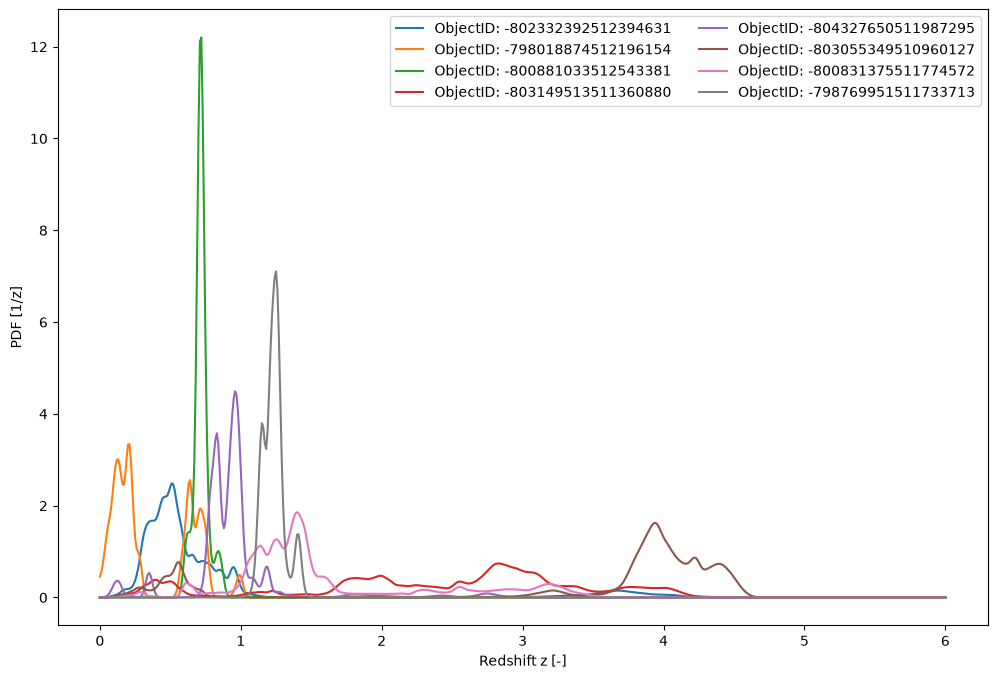

In [6]:
plt.figure(figsize=(12, 8))

for ii in range(8):
    # Parse the PDF string into a numpy array
    pdf = np.fromstring(res['phz_pdf'][ii][1:-1], dtype=float, sep=',')
    
    plt.plot(np.arange(0, 6.01, 0.01), pdf, label=f'ObjectID: {res['object_id'][ii]}')

plt.legend(ncols=2)
plt.xlabel('Redshift z [-]')
plt.ylabel('PDF [1/z]')

## Plot the Median Photo-Z Redshift of these 2000 Objects

Text(0, 0.5, 'Count [-]')

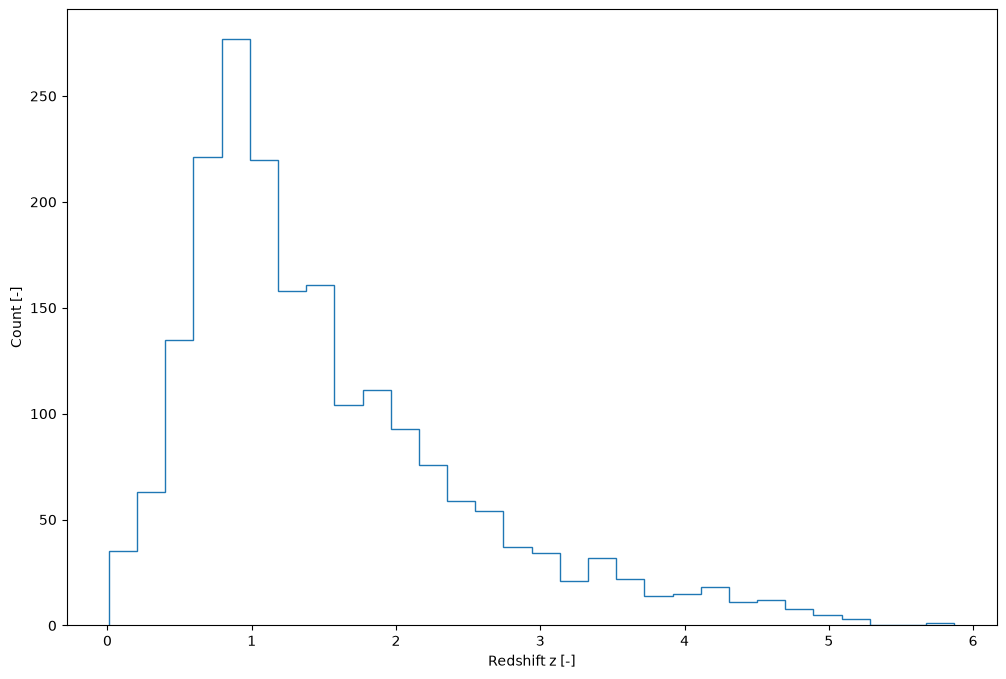

In [7]:
plt.figure(figsize=(12, 8))

plt.hist(res['phz_median'], bins=30, histtype='step')

plt.xlabel('Redshift z [-]')
plt.ylabel('Count [-]')